# Phần IV — Bài 2: Văn phòng phẩm (10 giao dịch)

Dữ liệu lấy từ đúng các ô đánh dấu **x** trên trang 44; **min_sup = 30%**, **min_conf = 80%**.

**Họ tên:** Nguyễn Lộc  \n**MSSV:** 6451071043  \n**Nguồn đề:** *Tàu liệu LAB1.pdf*, trang 43–45.  \n**Dữ liệu:** nhập trực tiếp từ bảng trong PDF; không cần tải thêm file.

> Chạy **Runtime → Run all** trên Colab. Mỗi notebook độc lập và có lệnh in họ tên/MSSV.

In [1]:
HO_TEN='NGUYỄN LỘC'
MSSV='6451071043'
print(f'Họ tên: {HO_TEN} | MSSV: {MSSV}')

Họ tên: NGUYỄN LỘC | MSSV: 6451071043


In [2]:
from itertools import combinations
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def support_count(transactions, itemset):
    s=set(itemset)
    return sum(s.issubset(set(t)) for t in transactions)

def apriori_manual(transactions, min_support_count):
    """Thuật toán Apriori: join + prune ở mỗi mức k."""
    transactions=[frozenset(t) for t in transactions]
    n=len(transactions)
    all_items=sorted(set().union(*transactions))
    candidates=[frozenset([x]) for x in all_items]
    levels=[]; counts={}
    k=1
    while candidates:
        level={c:support_count(transactions,c) for c in candidates}
        frequent={c:cnt for c,cnt in level.items() if cnt>=min_support_count}
        if not frequent: break
        levels.append(frequent)
        counts.update(frequent)
        prev=set(frequent)
        candidate_next=set()
        for a,b in combinations(sorted(prev,key=lambda z:tuple(sorted(z))),2):
            merged=a|b
            if len(merged)==k+1 and all(frozenset(s) in prev for s in combinations(merged,k)):
                candidate_next.add(merged)
        candidates=sorted(candidate_next,key=lambda x:tuple(sorted(x)))
        k+=1
    return levels,counts

def itemsets_table(counts,n):
    rows=[{'k':len(items),'Tập phổ biến':', '.join(sorted(items)), 'Support count':cnt, 'Support':round(cnt/n,5)} for items,cnt in counts.items()]
    return pd.DataFrame(rows).sort_values(['k','Tập phổ biến']).reset_index(drop=True) if rows else pd.DataFrame(columns=['k','Tập phổ biến','Support count','Support'])

def rules_from_counts(counts, transactions, min_conf, *, target_prefix=None):
    n=len(transactions)
    rows=[]
    for whole,both_count in counts.items():
        if len(whole)<2: continue
        for size in range(1,len(whole)):
            for left_tuple in combinations(sorted(whole),size):
                left=frozenset(left_tuple)
                right=whole-left
                if target_prefix is not None and not (len(right)==1 and next(iter(right)).startswith(target_prefix)):
                    continue
                left_count=support_count(transactions,left)
                right_count=support_count(transactions,right)
                conf=both_count/left_count
                if conf+1e-12>=min_conf:
                    rows.append({'Vế trái':', '.join(sorted(left)), 'Vế phải':', '.join(sorted(right)),
                                 'Support count':both_count,'Support':round(both_count/n,5),
                                 'Confidence':round(conf,5),'Lift':round(conf/(right_count/n),5)})
    return pd.DataFrame(rows).sort_values(['Confidence','Support','Vế trái'],ascending=[False,False,True]).reset_index(drop=True) if rows else pd.DataFrame(columns=['Vế trái','Vế phải','Support count','Support','Confidence','Lift'])

def plot_rules(rules,title):
    if len(rules)==0:
        print('Không có luật nào vượt qua ngưỡng nên không vẽ scatter.')
        return
    fig,ax=plt.subplots(figsize=(7,4.2))
    ax.scatter(rules['Support'],rules['Confidence'],s=65,alpha=.8)
    ax.set(xlabel='Support',ylabel='Confidence',title=title)
    ax.grid(alpha=.3)
    plt.tight_layout();plt.show()


## Chuyển bảng dấu x thành giỏ hàng

In [3]:
# Bài 2 — đọc từng dấu x trong bảng trang 44
transactions=[
    ['COMPA','TẬP TRẮNG','BÚT BI'],           # T1
    ['KÉO','THƯỚC','TẬP TRẮNG','BÚT BI'],    # T2
    ['COMPA','TẬP TRẮNG','BÚT BI'],          # T3
    ['KÉO','COMPA','TẬP TRẮNG','BÚT BI'],    # T4
    ['THƯỚC'],                              # T5
    ['BÚT BI'],                             # T6
    ['TẬP TRẮNG'],                          # T7
    ['TẨY'],                                # T8
    ['BÚT MÀU','TẨY'],                      # T9
    ['BÚT MÀU']                             # T10
]
min_sup=.30;min_conf=.80
min_count=3
display(pd.DataFrame({'TID':[f'T{i}' for i in range(1,11)],'Items':[', '.join(t) for t in transactions]}))
print('Ngưỡng support count:',min_count,'/10 giao dịch | confidence:',min_conf)


,TID,Items
0,T1,"COMPA, TẬP TRẮNG, BÚT BI"
1,T2,"KÉO, THƯỚC, TẬP TRẮNG, BÚT BI"
2,T3,"COMPA, TẬP TRẮNG, BÚT BI"
3,T4,"KÉO, COMPA, TẬP TRẮNG, BÚT BI"
4,T5,THƯỚC
5,T6,BÚT BI
6,T7,TẬP TRẮNG
7,T8,TẨY
8,T9,"BÚT MÀU, TẨY"
9,T10,BÚT MÀU


Ngưỡng support count: 3 /10 giao dịch | confidence: 0.8


## Apriori và luật kết hợp

L1: 3 tập phổ biến
L2: 3 tập phổ biến
L3: 1 tập phổ biến


,k,Tập phổ biến,Support count,Support
0,1,BÚT BI,5,0.5
1,1,COMPA,3,0.3
2,1,TẬP TRẮNG,5,0.5
3,2,"BÚT BI, COMPA",3,0.3
4,2,"BÚT BI, TẬP TRẮNG",4,0.4
5,2,"COMPA, TẬP TRẮNG",3,0.3
6,3,"BÚT BI, COMPA, TẬP TRẮNG",3,0.3


Số luật hợp lệ: 7


,Vế trái,Vế phải,Support count,Support,Confidence,Lift
0,"BÚT BI, COMPA",TẬP TRẮNG,3,0.3,1.0,2.0
1,COMPA,BÚT BI,3,0.3,1.0,2.0
2,COMPA,TẬP TRẮNG,3,0.3,1.0,2.0
3,COMPA,"BÚT BI, TẬP TRẮNG",3,0.3,1.0,2.5
4,"COMPA, TẬP TRẮNG",BÚT BI,3,0.3,1.0,2.0
5,BÚT BI,TẬP TRẮNG,4,0.4,0.8,1.6
6,TẬP TRẮNG,BÚT BI,4,0.4,0.8,1.6


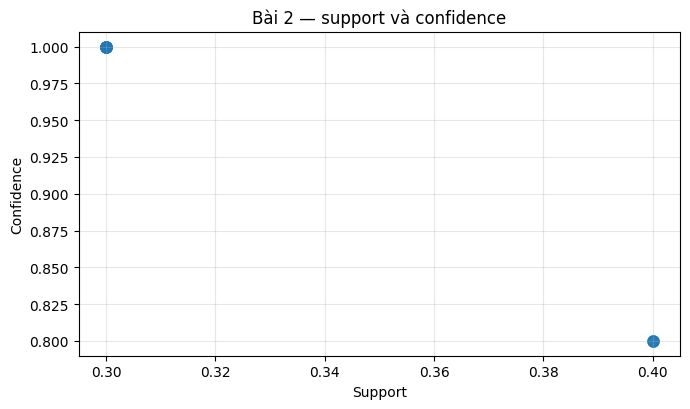

In [4]:
levels, counts=apriori_manual(transactions,min_count)
for k,lev in enumerate(levels,1):print(f'L{k}: {len(lev)} tập phổ biến')
display(itemsets_table(counts,len(transactions)))
rules=rules_from_counts(counts,transactions,min_conf)
print('Số luật hợp lệ:',len(rules));display(rules)
plot_rules(rules,'Bài 2 — support và confidence')
